# بک‌تست صادقانه یک استراتژی روند روی طلا

**آموزشی است و توصیه سرمایه‌گذاری نیست.** این نوت‌بوک استراتژی پیشنهاد نمی‌کند. هدفش نشان دادن **روش درست ارزیابی** است، حتی وقتی نتیجه «خوب» نیست.

استراتژی ساده است: طلا را وقتی بخر که میانگین متحرک کوتاه بالای میانگین متحرک بلند باشد، وگرنه نقد بمان (long/flat، بدون اهرم). سؤال این است: **آیا این روی طلا واقعاً کار می‌کند، یا فقط در یک بازه و با یک پارامتر خوش‌شانس بوده؟**

برای جواب، چند چیز را عمداً رعایت می‌کنیم:

1. **بدون نگاه به آینده:** سیگنال امروز فقط برای فردا استفاده می‌شود (`shift(1)`).
2. **هزینه معامله** را حساب می‌کنیم.
3. **پارامتر را فقط روی یک بازه انتخاب می‌کنیم** و روی بازه دیگر امتحان می‌کنیم.
4. **با شانس مقایسه می‌کنیم:** آیا نتیجه از زمان‌بندی تصادفی با همان میزان حضور در بازار قابل‌تشخیص است؟

**داده:** قیمت اونس روزانه از TGJU (۱۹۸۰ تا ۲۰۲۶). فقط از ۲۰۰۰-۰۹ منبع دوم داریم؛ ۱۹۸۰ تا ۱۹۹۹ یک منبع و یک قیمت در روز است و فقط به‌عنوان آزمون مستقل اضافه می‌شود. داده در repo ذخیره نیست و نوت‌بوک آن را می‌گیرد.

In [1]:
import itertools, json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") if Path("../scripts/fetch_data.py").exists() else Path(".")  # repo checkout or Colab
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)
(ROOT / "images").mkdir(exist_ok=True)

def load_ons():
    f = DATA / "ons_usd.csv"
    if not f.exists():  # data is not stored in the repository
        url = "https://api.tgju.org/v1/market/indicator/summary-table-data/ons"
        rows = json.load(urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=60))["data"]
        num = lambda t: float(t.replace(",", ""))
        pd.DataFrame([(r[6].replace("/", "-"), *map(num, r[:4])) for r in rows],
                     columns=["date", "open", "low", "high", "close"]).sort_values("date").to_csv(f, index=False)
    return pd.read_csv(f, parse_dates=["date"]).set_index("date")["close"]

price = load_ons()
ret = price.pct_change().dropna()          # simple daily returns
IS, OOS1, OOS2 = ("2000-09", "2012"), ("2013", "2026"), ("1980", "1999")   # in-sample, out-of-sample, early history
print(f"{len(price)} prices, {price.index[0].date()} to {price.index[-1].date()}")

12168 prices, 1979-12-26 to 2026-10-16


## ۱. تعریف استراتژی و ابزار ارزیابی

- **سیگنال:** `۱` اگر میانگین متحرک ساده `fast` روزه بالاتر از میانگین `slow` روزه باشد، وگرنه `۰`.
- **موقعیت امروز = سیگنال دیروز.** سیگنال دیروز با قیمت بسته‌شدن دیروز ساخته شده و برای بازده امروز به‌کار می‌رود.
- **هزینه:** به‌ازای هر تغییر موقعیت، بخشی از سرمایه (پیش‌فرض ۰٫۰۵٪) کم می‌شود. این عدد را حدسی گذاشته‌ایم؛ حساسیتش را پایین‌تر می‌سنجیم.
- **سنجه‌ها:** نسبت شارپ سالانه (میانگین ÷ انحراف معیار × √۲۵۲، بدون نرخ بدون ریسک)، رشد مرکب سالانه (CAGR) و بیشترین افت (max drawdown).

In [2]:
def signal(fast, slow):
    ma_f, ma_s = price.rolling(fast).mean(), price.rolling(slow).mean()
    s = (ma_f > ma_s).astype(float)
    s[ma_s.isna()] = np.nan
    return s

def backtest(fast, slow, cost=0.0005, lag=1):
    pos = signal(fast, slow).shift(lag).reindex(ret.index)       # lag=1: yesterday's signal, today's return
    net = pos * ret - cost * pos.diff().abs().fillna(0)
    return net, pos

def summary(r):
    r = r.dropna()
    eq = (1 + r).cumprod()
    return {"sharpe": r.mean() / r.std() * np.sqrt(252),
            "CAGR": eq.iloc[-1] ** (252 / len(r)) - 1,
            "vol": r.std() * np.sqrt(252),
            "max drawdown": (eq / eq.cummax() - 1).min()}

periods = {"1980-1999": OOS2, "2000-09..2012": IS, "2013..2026": OOS1}
pd.DataFrame({name: summary(ret[a:b]) for name, (a, b) in periods.items()}).T.round(3).rename_axis("buy and hold")

,sharpe,CAGR,vol,max drawdown
buy and hold,,,,
1980-1999,-0.041,-0.028,0.199,-0.698
2000-09..2012,0.863,0.151,0.183,-0.290
2013..2026,0.476,0.066,0.161,-0.378


سه بازه خیلی متفاوت‌اند. **خرید و نگه‌داشتن** طلا در ۱۹۸۰ تا ۱۹۹۹ شارپ تقریباً صفر (۰٫۰۴-) و CAGR منفی (۲٫۸٪-) داشت، با افت ۷۰٪. در ۲۰۰۰-۰۹ تا ۲۰۱۲ شارپ ۰٫۸۶ و CAGR ۱۵٪ بود، و در ۲۰۱۳ تا ۲۰۲۶ شارپ ۰٫۴۸ و CAGR ۶٫۶٪. هر نتیجه‌ای که فقط از یک بازه بیاید، به همان بازه وابسته است.

## ۲. نگاه به آینده چقدر نتیجه را دروغین می‌کند؟

اگر `lag=0` بگذاریم، سیگنالِ همان روز برای بازده همان روز استفاده می‌شود، که در عمل ممکن نیست. اثرش را روی دو استراتژی می‌بینیم: یکی با میانگین‌های **کند** (۵۰ و ۲۰۰) و یکی **سریع** (۵ و ۲۰):

In [3]:
rows = {}
for fast, slow in [(50, 200), (5, 20)]:
    for lag in (1, 0):
        r, _ = backtest(fast, slow, lag=lag)
        rows[f"MA {fast}/{slow}, lag={lag}"] = summary(r["2000-09":])
pd.DataFrame(rows).T.round(3)

,sharpe,CAGR,vol,max drawdown
"MA 50/200, lag=1",0.688,0.091,0.141,-0.338
"MA 50/200, lag=0",0.709,0.094,0.141,-0.346
"MA 5/20, lag=1",0.457,0.052,0.129,-0.237
"MA 5/20, lag=0",0.981,0.125,0.129,-0.194


- برای میانگین‌های **کند** (۵۰/۲۰۰) فرق ناچیز است (شارپ ۰٫۶۹ در برابر ۰٫۷۱).
- برای میانگین‌های **سریع** (۵/۲۰) نگاه به آینده شارپ را از ۰٫۴۶ به ۰٫۹۸ می‌رساند، یعنی **بیش از دو برابر**، و CAGR را از ۵٫۲٪ به ۱۲٫۵٪.

هرچه سیگنال سریع‌تر باشد، خطای نگاه به آینده بزرگ‌تر است. ولی حتی وقتی اثرش ناچیز است، آن را همیشه حذف کن: `shift(1)` باید عادت باشد، نه چیزی که فقط گاهی بزنی.

## ۳. انتخاب پارامتر روی یک بازه

شبکه‌ای از پارامترها را روی بازه **in-sample** (۲۰۰۰-۰۹ تا ۲۰۱۲) امتحان می‌کنیم: `fast` از ۱۰ تا ۱۰۰ و `slow` از ۱۰۰ تا ۲۵۰ (فقط `fast < slow`).

In [4]:
fasts, slows = [10, 20, 30, 50, 75, 100], [100, 150, 200, 250]
grid = [(f, s) for f, s in itertools.product(fasts, slows) if f < s]
is_sharpe = pd.Series({k: summary(backtest(*k)[0][IS[0]:IS[1]])["sharpe"] for k in grid})
print(f"{len(grid)} parameter pairs tried")
is_sharpe.unstack().round(2).rename_axis("fast").rename_axis("slow", axis=1)

23 parameter pairs tried


slow,100,150,200,250
fast,,,,
10,0.51,0.70,0.70,0.71
20,0.54,0.70,0.67,0.79
30,0.63,0.64,0.75,0.89
50,0.80,0.81,0.81,0.80
75,0.88,0.76,0.83,0.87
100,NaN,0.79,0.83,0.84


In [5]:
best = is_sharpe.idxmax()
print("best in-sample pair:", best, "| in-sample Sharpe", round(is_sharpe.max(), 2))
bh_is = summary(ret[IS[0]:IS[1]])
print(f"buy and hold in the same period: Sharpe {bh_is['sharpe']:.2f}, CAGR {bh_is['CAGR']:.1%}, max drawdown {bh_is['max drawdown']:.1%}")
print(f"spread across the grid: {is_sharpe.min():.2f} .. {is_sharpe.max():.2f}")

best in-sample pair: (np.int64(30), np.int64(250)) | in-sample Sharpe 0.89
buy and hold in the same period: Sharpe 0.86, CAGR 15.1%, max drawdown -29.0%
spread across the grid: 0.51 .. 0.89


- ۲۳ جفت امتحان شد و شارپ in-sample از ۰٫۵۱ تا ۰٫۸۹ پخش است. بهترین، `(۳۰، ۲۵۰)` با ۰٫۸۹.
- خرید و نگه‌داشتن در همان بازه ۰٫۸۶ داشت. یعنی بهترین پارامتر فقط **۰٫۰۳** از خرید و نگه‌داشتن بهتر است (با افت کمتر: ۲۲٪- در برابر ۲۹٪-). همسایه‌های آن در جدول (۰٫۸۰ تا ۰٫۸۸) تفاوت معناداری ندارند.

انتخاب «بهترین» از میان ۲۳ جفت یعنی ۲۳ بار شانس دادن؛ این فاصله ۰٫۰۳ را نمی‌توان مهارت دانست.

## ۴. آزمون روی داده‌ای که ندیده‌ایم

همان جفت پارامتر را، بدون هیچ تغییری، روی دو بازه دیگر اجرا می‌کنیم: ۲۰۱۳ تا ۲۰۲۶ و ۱۹۸۰ تا ۱۹۹۹ (که اصلاً در انتخاب نقشی نداشتند):

In [6]:
net, pos = backtest(*best)
rows = {}
for name, (a, b) in periods.items():
    st = summary(net[a:b])
    st["time in market"] = pos[a:b].mean()
    st["trades per year"] = pos[a:b].diff().abs().sum() / (len(net[a:b]) / 252)
    rows[f"strategy {best[0]}/{best[1]}, {name}"] = st
    rows[f"buy and hold, {name}"] = {**summary(ret[a:b]), "time in market": 1.0, "trades per year": 0.0}
pd.DataFrame(rows).T.round(3)

,sharpe,CAGR,vol,max drawdown,time in market,trades per year
"strategy 30/250, 1980-1999",-0.123,-0.019,0.108,-0.460,0.368,1.270
"buy and hold, 1980-1999",-0.041,-0.028,0.199,-0.698,1.000,0.000
"strategy 30/250, 2000-09..2012",0.894,0.140,0.161,-0.222,0.864,0.549
"buy and hold, 2000-09..2012",0.863,0.151,0.183,-0.290,1.000,0.000
"strategy 30/250, 2013..2026",0.410,0.045,0.127,-0.291,0.602,1.741
"buy and hold, 2013..2026",0.476,0.066,0.161,-0.378,1.000,0.000


- **۲۰۱۳ تا ۲۰۲۶:** شارپ **۰٫۴۱** در برابر ۰٫۴۸ برای خرید و نگه‌داشتن، و CAGR ۴٫۵٪ در برابر ۶٫۶٪. ولی افت کمتر (۲۹٪- در برابر ۳۸٪-) و نوسان کمتر (۱۲٫۷٪ در برابر ۱۶٫۱٪)، چون فقط ۶۰٪ زمان در بازار است و حدود ۱٫۷ معامله در سال دارد.
- **۱۹۸۰ تا ۱۹۹۹:** شارپ ۰٫۱۲- در برابر ۰٫۰۴-؛ افت ۴۶٪- در برابر ۷۰٪-. استراتژی باز هم افت را کم کرد ولی سود نداد.

یعنی روی داده ندیده، استراتژی از نظر شارپ **بهتر از خرید و نگه‌داشتن نبود**؛ چیزی که تغییر کرد ریسک بود (افت و نوسان کمتر)، نه بازدهِ تعدیل‌شده با ریسک.

## ۵. هزینه معامله

In [7]:
print("out-of-sample 2013-2026 Sharpe by cost per position change:")
for c in (0, 0.0005, 0.001, 0.002):
    print(f"  {c:.2%}: {summary(backtest(*best, cost=c)[0]['2013':'2026'])['sharpe']:.2f}")

out-of-sample 2013-2026 Sharpe by cost per position change:
  0.00%: 0.42
  0.05%: 0.41
  0.10%: 0.40
  0.20%: 0.39


هزینه در این استراتژی مسئله اصلی نیست: شارپ از ۰٫۴۲ (بدون هزینه) تا ۰٫۳۹ (۰٫۲٪ هر معامله) تغییر می‌کند، چون فقط حدود ۱٫۷ معامله در سال دارد. (برای استراتژی‌های سریع‌تر، تعداد معاملات خیلی بیشتر است و هزینه مهم می‌شود؛ این‌جا نیازموده‌ایم.)

## ۶. با شانس مقایسه کنیم

اگر استراتژی واقعاً زمان‌بندی خوبی داشت، باید بهتر از **زمان‌بندی تصادفی با همان میزان حضور در بازار** باشد. همان رشته موقعیت‌ها را به‌صورت دوری (circular) جابه‌جا می‌کنیم (ساختار و تعداد معاملات حفظ می‌شود ولی هم‌زمانی با قیمت از بین می‌رود) و شارپ را ۲٬۰۰۰ بار حساب می‌کنیم:

In [8]:
p = pos["2013":"2026"].dropna()
r = ret["2013":"2026"].reindex(p.index).to_numpy()
x = p.to_numpy()
sharpe = lambda z: z.mean() / z.std() * np.sqrt(252)
obs = sharpe(x * r)
rng = np.random.default_rng(1)
null = np.array([sharpe(np.roll(x, rng.integers(252, len(x) - 252)) * r) for _ in range(2000)])
print(f"observed (gross of cost) Sharpe: {obs:.2f}")
print(f"random timing with the same exposure: mean {null.mean():.2f}, 5th-95th percentile [{np.percentile(null, 5):.2f}, {np.percentile(null, 95):.2f}]")
print(f"share of random timings at least as good: {(null >= obs).mean():.0%}")

observed (gross of cost) Sharpe: 0.42
random timing with the same exposure: mean 0.32, 5th-95th percentile [0.11, 0.55]
share of random timings at least as good: 27%


۲۷٪ از زمان‌بندی‌های تصادفی همان‌قدر خوب یا بهتر بودند (شارپ مشاهده‌شده ۰٫۴۲ داخل بازه ۵ تا ۹۵ درصدی تصادفی‌ها، یعنی ۰٫۱۱ تا ۰٫۵۵ است). با این داده **نمی‌توانیم** بگوییم این استراتژی زمان‌بندی بهتر از شانس دارد.

## ۷. آیا بهترین پارامتر in-sample در out-of-sample هم بهترین است؟

همه جفت‌های شبکه را روی ۲۰۱۳ تا ۲۰۲۶ هم اجرا می‌کنیم و شارپ in-sample را با out-of-sample مقایسه می‌کنیم:

correlation of in-sample and out-of-sample Sharpe across the grid: -0.22
out-of-sample Sharpe across the grid: min 0.41, median 0.52, max 0.68; buy and hold 0.48
our in-sample winner (np.int64(30), np.int64(250)) ranks 22 of 23 out of sample
pairs beating buy and hold on Sharpe out of sample: 74%
max drawdown out of sample: grid median -26.4%, buy and hold -37.8%


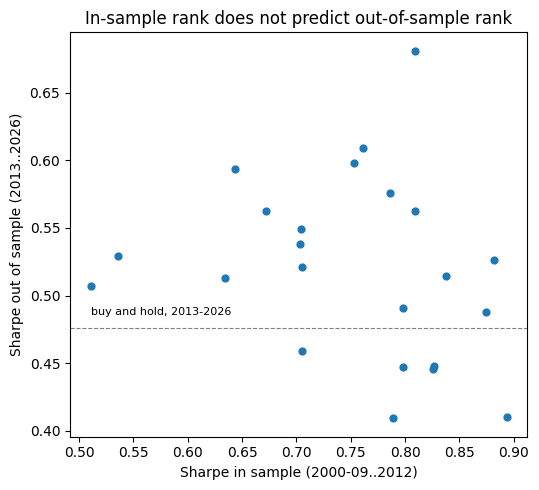

In [9]:
oos_sharpe = pd.Series({k: summary(backtest(*k)[0][OOS1[0]:OOS1[1]])["sharpe"] for k in grid})
oos_dd = pd.Series({k: summary(backtest(*k)[0][OOS1[0]:OOS1[1]])["max drawdown"] for k in grid})
bh_oos = summary(ret[OOS1[0]:OOS1[1]])
print(f"correlation of in-sample and out-of-sample Sharpe across the grid: {is_sharpe.corr(oos_sharpe):+.2f}")
print(f"out-of-sample Sharpe across the grid: min {oos_sharpe.min():.2f}, median {oos_sharpe.median():.2f}, max {oos_sharpe.max():.2f}; buy and hold {bh_oos['sharpe']:.2f}")
print(f"our in-sample winner {best} ranks {int(oos_sharpe.rank(ascending=False)[best])} of {len(grid)} out of sample")
print(f"pairs beating buy and hold on Sharpe out of sample: {(oos_sharpe > bh_oos['sharpe']).mean():.0%}")
print(f"max drawdown out of sample: grid median {oos_dd.median():.1%}, buy and hold {bh_oos['max drawdown']:.1%}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(is_sharpe, oos_sharpe, s=24)
ax.axhline(bh_oos["sharpe"], color="gray", lw=0.8, ls="--"); ax.text(is_sharpe.min(), bh_oos["sharpe"] + 0.01, "buy and hold, 2013-2026", fontsize=8)
ax.set_xlabel("Sharpe in sample (2000-09..2012)"); ax.set_ylabel("Sharpe out of sample (2013..2026)")
ax.set_title("In-sample rank does not predict out-of-sample rank")
plt.tight_layout(); plt.savefig(ROOT / "images" / "trend-is-vs-oos.png", dpi=130); plt.show()

- همبستگی شارپ in-sample و out-of-sample در کل شبکه **۰٫۲۲-** است: جفتی که in-sample بهتر بود، out-of-sample به‌طور میانگین کمی بدتر بود.
- بهترین in-sample ما در out-of-sample رتبه ۲۲ از ۲۳ شد (شارپ ۰٫۴۱؛ کل شبکه از ۰٫۴۱ تا ۰٫۶۸، میانه ۰٫۵۲).
- ۷۴٪ جفت‌ها در out-of-sample از خرید و نگه‌داشتن (۰٫۴۸) بهتر بودند. ولی این بررسی **بعد از دیدن نتیجه** است، و جفت‌ها همه روی یک مسیر قیمت‌اند و مستقل نیستند؛ شواهد مستقل نیست.
- افت بیشینه در تمام شبکه کمتر از خرید و نگه‌داشتن بود: میانه ۲۶٪- در برابر ۳۸٪-.

## محدودیت‌ها

۱. **یک دارایی، یک مسیر تاریخی.** هر نتیجه‌ای به همین مسیر وابسته است.
۲. **نقد بدون بهره:** وقتی در بازار نیستیم، سود صفر حساب کرده‌ایم. در دهه ۱۹۸۰ نرخ بهره بالا بود؛ این به ضرر استراتژی است.
۳. **هزینه معامله حدسی است** و اجرا با قیمت بسته‌شدن فرض شده (در عمل لغزش قیمت هست).
۴. **۲۳ جفت پارامتر** امتحان شد و پنجره‌ها دلبخواهی‌اند. هر جفتی که در گذشته بهتر بوده، شاید شانس بوده.
۵. **داده:** TGJU غیررسمی است و قبل از ۲۰۰۰ یک منبع و یک قیمت در روز دارد.
۶. **هزینه نگهداری طلا** (نگهداری فیزیکی یا هزینه صندوق) را حساب نکرده‌ایم.

## جمع‌بندی

- **همیشه `shift(1)`:** با سیگنال سریع، نگاه به آینده شارپ را بیش از دو برابر کرد.
- **انتخاب بهترین پارامتر in-sample تضمینی برای out-of-sample نیست:** بهترین ما تقریباً بدترین شد.
- **با شانس مقایسه کن:** ۲۷٪ زمان‌بندی‌های تصادفی همان‌قدر خوب بودند.
- نتیجه صادقانه: روی طلا، این استراتژی روند **افت و نوسان را کم کرد** ولی **شارپ را بالاتر از خرید و نگه‌داشتن نبرد**، و شواهدی نداریم که زمان‌بندی‌اش از شانس بهتر باشد.

این توصیف گذشته است و پیشنهاد معامله نیست.